In [63]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))


<div align="center">
  <img src="masksolutionslogo.png" alt="MASK Solutions Logo" width="350">
</div>


<div align="center">

# LE SHOPPE
## Customer Retention Intelligence
### Predictive analytics, risk prioritisation and retention decision support


---
</div>


<h1 align="center">Guide</h1>

Section | Purpose
|---|---|
| Data preparation and initial exploration | Inspect source data, missingness, distributions and candidate features |
| Customer segmentation | Explore whether behavioural clusters add useful context to churn analysis |
| Customer economics | Explore acquisition cost, lifetime value and transaction-based business measures |
| Model experimentation | Tune and compare CatBoost, Random Forest, XGBoost, LightGBM and stacking |
| Final model comparison | Compare feature sets and evaluation metrics |
| Risk labels | Convert model probabilities into operational risk tiers |
| Deployment handover | Record how the selected model is packaged and connected to the app/AWS environment |

## 1. Introduction

#### 1.1 Background

Le Shoppe currently uses two main approaches to reconnect with customers who have stopped shopping with the business or become less active. The first is an annual “welcome back” email campaign, which offers discounts to customers who have not made a purchase in 12 months. The second involves the Customer Care team contacting less active customers during quieter periods, with the option of offering discounts or free products to encourage them to return.

While these approaches can help bring customers back, they have some limitations. Both rely on staff manually generating customer lists, which takes time and requires someone with the right knowledge and access to complete the process. By the time a list reaches the Customer Care team or an offer is sent to a customer, the information may already be outdated. This means Le Shoppe may be missing opportunities to reach customers at the right time.

Another challenge is understanding why customers stop shopping with Le Shoppe. Although individual customer feedback can provide some insight, it does not necessarily show the broader patterns or behaviours that may be linked to churn.

#### 1.2 Project objectives

The aim of this project is to investigate how machine learning and predictive analytics could help Le Shoppe improve its customer retention process. 

**The project focuses on three main objectives:**

- **Identify customers at risk** of churning so that Le Shoppe can prioritise who to contact and when.

- **Identify patterns** associated with churn by exploring customer behaviour and investigating which factors may contribute to customers becoming less active.

- **Recommend ways to improve customer retention** by using the findings to suggest more targeted and effective approaches to customer outreach.

#### 1.3 Expected business value

By using customer data to identify potential churn earlier, Le Shoppe could move away from relying solely on annual campaigns and manually generated lists. Instead, the business could use predicted churn risk to help prioritise outreach, make better use of the Customer Care team's time, and provide customers with more relevant retention offers.

The project will evaluate different machine learning models to determine how effectively they identify customers at risk of churning. The results will also be used to explore potential churn drivers and develop practical recommendations for Le Shoppe's Marketing, Customer Care and Ecommerce Operations teams.

The overall goal is to develop a solution that does more than predict churn. It should help Le Shoppe understand its customers better and make more informed decisions about how to retain them.

## 2. Helper functions

Before starting the analysis, we defined a few helper functions that could be reused throughout the project. These were used to calculate ratios, evaluate model performance and group customers into different churn risk categories based on their predicted probabilities.

Having these functions available helped keep the code consistent and reduced the need to repeat the same calculations throughout the notebook.

In [12]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
import umap
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, recall_score, precision_score, f1_score, cohen_kappa_score, roc_auc_score, RocCurveDisplay
from scipy.stats import friedmanchisquare
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
from collections import Counter
import shap
import pickle

imputer = SimpleImputer(strategy='median')

In [13]:
def get_ratio(a, b):
    decimal_ratio = a / b
    
    return f"{decimal_ratio:.1f}:1"

def assign_risk_tier(prob, lowtier, medtier):
    if prob < lowtier:
        return 'Low'
    elif prob < medtier:
        return 'Med'
    else:
        return 'High'

def determine_best_risk_thresholds(y_proba, y_test, low_thresholds, med_thresholds, chosen_metric='f1_low'):
    y_test_mapped = np.where(y_test == 0, 'Low', 'High')
    results_list = []
    
    for low_t in low_thresholds:
        for med_t in med_thresholds:
            if low_t >= med_t:
                continue
                
            y_pred_risk = np.array([assign_risk_tier(p, low_t, med_t) for p in y_proba])
            
            report = classification_report(y_test_mapped,y_pred_risk,labels=['Low', 'Med', 'High'],zero_division=0,output_dict=True)
            
            results_list.append({
                'low_cutoff': low_t,
                'med_cutoff': med_t,
                'precision (low)': report['Low']['precision'],
                'recall (low)': report['Low']['recall'],
                'f1-score (low)': report['Low']['f1-score'],
                'precision (high)': report['High']['precision'],
                'recall (high)': report['High']['recall'],
                'f1-score (high)': report['High']['f1-score'],
                'accuracy': report['accuracy']
            })
            
    df_results = pd.DataFrame(results_list)
    
    if chosen_metric == 'f1_low':
        target_metric = 'f1-score (low)'
    elif chosen_metric == 'f1_high':
        target_metric = 'f1-score (high)'
    elif chosen_metric == 'precision_low':
        target_metric = 'precision (low)'
    elif chosen_metric == 'precision_high':
        target_metric = 'precision (high)'
    elif chosen_metric == 'recall_low':
        target_metric = 'recall (low)'
    elif chosen_metric == 'recall_high':
        target_metric = 'recall (high)'
    elif chosen_metric == 'accuracy':
        target_metric = 'accuracy'

    df_best = df_results.sort_values(by=target_metric, ascending=False).head(1)

    results = pd.DataFrame({"Metric": ["Precision","Recall","F1 Score"],
               "Low": [df_best['precision (low)'].iloc[0], df_best['recall (low)'].iloc[0], df_best['f1-score (low)'].iloc[0]],
               "High": [df_best['precision (high)'].iloc[0], df_best['recall (high)'].iloc[0], df_best['f1-score (high)'].iloc[0]]})

    results.set_index('Metric', inplace=True)
    results.index.rename('', inplace=True)
    print(f"""Best Results
----------------------------------------------
Low threshold: {df_best['low_cutoff'].iloc[0]}
Medium threshold: {df_best['med_cutoff'].iloc[0]}
Accuracy: {df_best['accuracy'].iloc[0]}
{results}""")

    return df_best['low_cutoff'].iloc[0], df_best['med_cutoff'].iloc[0]

def apply_risk_label(row):
    if row['churn_probability'] < 0.3:
        return 'Low'
    elif row['churn_probability'] > 0.3 and row['churn_probability'] <= 0.4:
        return 'Medium'
    else:
        return 'High'

def specificity_score(y_true, y_pred):
    return recall_score(y_true, y_pred, pos_label=0)

## 3. Data preparation and initial exploration
Before getting into the modelling, we first needed to understand the data Le Shoppe had available and whether there were any issues that could affect the results. This section explored the customer dataset, including the types of information collected, any missing values, and the behaviours that might help identify customers who were at risk of churning.
We explored the distributions of the features and how they related to each other, as well as looking at feature importance to identify which variables could be useful for predicting churn. These findings helped guide decisions around data preparation and which features to use in the models. However, feature importance showed which variables the models found useful, rather than proving that a particular behaviour caused a customer to churn.
We also documented how missing values and other data preparation steps were handled. To make sure the model evaluation was fair, preprocessing steps that learned from the data were fitted on the training set only, rather than using information from the test set.

In [16]:
churn_dataset = pd.read_csv('ecommerce_customer_churn_dataset.csv')

In [17]:
churn_dataset.dtypes

Age                              float64
Gender                            object
Country                           object
City                              object
Membership_Years                 float64
Login_Frequency                  float64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Payment_Method_Diversity         float64
Lifetime_Value                   float64
Credit_Balance                   float64
Churned                            int64
Signup_Quarter  

In [18]:
churn_dataset.isna().sum()

Age                              2495
Gender                              0
Country                             0
City                                0
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate               0
Wishlist_Items                   4000
Total_Purchases                     0
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3500
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Payment_Method_Diversity         2500
Lifetime_Value                      0
Credit_Balance                   5500
Churned                             0
Signup_Quarter                      0
dtype: int64

In [19]:
encoder = OneHotEncoder(sparse_output=False)
encoded_array = encoder.fit_transform(churn_dataset[['Gender','Country','City','Signup_Quarter']])

encoded_df = pd.DataFrame(encoded_array, columns=encoder.get_feature_names_out(['Gender','Country','City','Signup_Quarter']))
churn_dataset_encoded = churn_dataset.drop(['Gender','Country','City','Signup_Quarter'], axis=1)
churn_dataset_encoded = pd.concat([churn_dataset_encoded, encoded_df], axis=1)

In [20]:
y = churn_dataset_encoded['Churned']
X = churn_dataset_encoded.drop('Churned', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
rf_helper = RandomForestClassifier(n_estimators=100, random_state=42)
rf_helper.fit(X_train, y_train)

importances = rf_helper.feature_importances_
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

In [22]:
top20feature_importance_df = feature_importance_df.head(20)
top20feature_importance_df

,Feature,Importance
13,Customer_Service_Calls,0.113862
18,Lifetime_Value,0.108101
5,Cart_Abandonment_Rate,0.082969
0,Age,0.061734
10,Discount_Usage_Rate,0.056280
9,Days_Since_Last_Purchase,0.052057
12,Email_Open_Rate,0.045517
8,Average_Order_Value,0.043546
7,Total_Purchases,0.042794
3,Session_Duration_Avg,0.042641


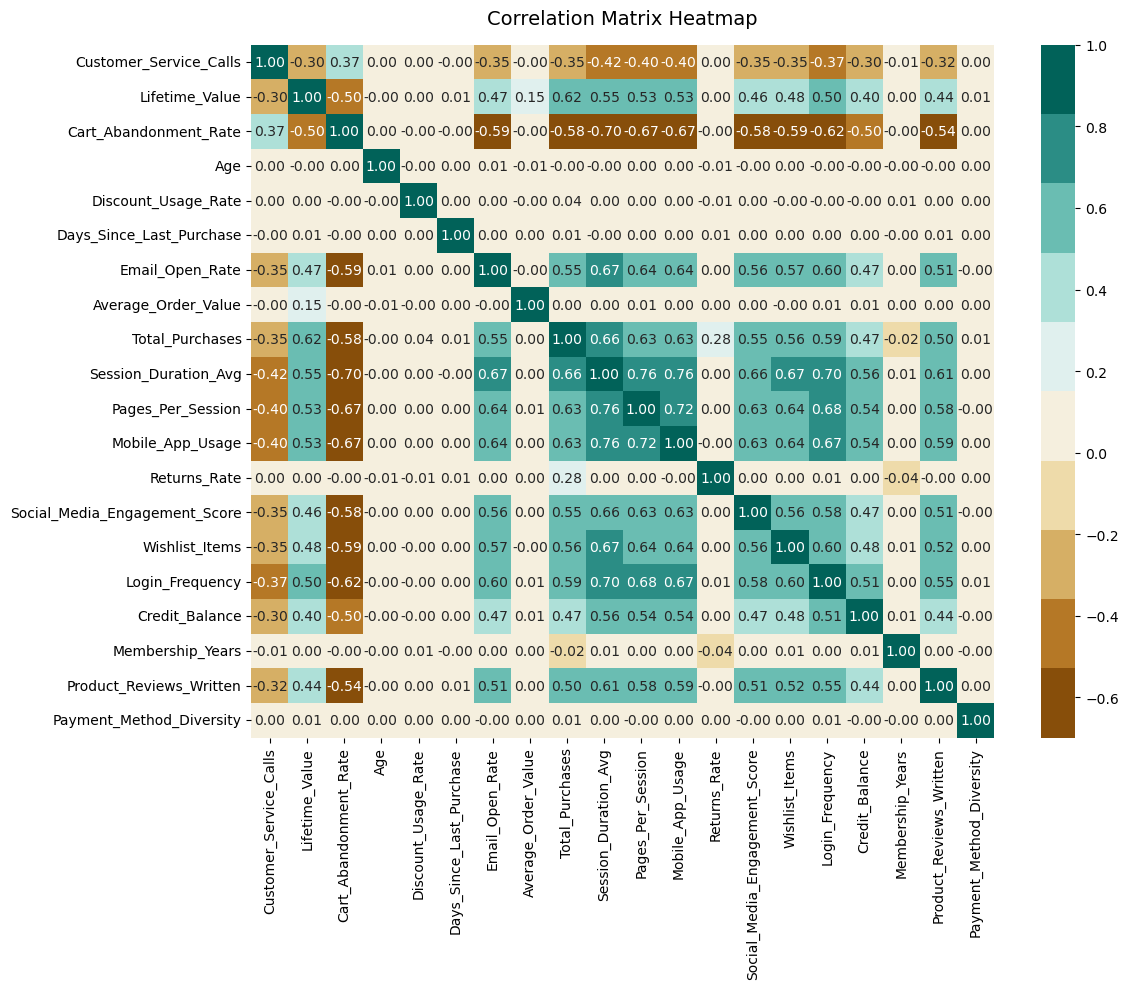

In [23]:
feature_names_top20 = top20feature_importance_df['Feature'].tolist()

corr_matrix = churn_dataset_encoded[feature_names_top20].corr()

plt.figure(figsize=(12, 10))
colormap = sns.color_palette("BrBG",10)

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap=colormap)

plt.title("Correlation Matrix Heatmap", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### Initial feature selection findings

The initial feature importance results and correlation heatmap helped identify which variables might be useful for predicting customer churn. Lifetime value stood out as the strongest feature, while several customer engagement and purchasing behaviours also appeared worth investigating.

Based on these initial findings, the features were grouped according to their potential usefulness:

**Strongest feature**
- `Lifetime_Value`

**Supporting features (higher correlation)**
- `Total_Purchases`
- `Session_Duration_Average`
- `Pages_Per_Session`
- `Mobile_App_Usage`
- `Login_Frequency`
- `Cart_Abandonment_Rate`

**Potentially helpful features (moderate correlation)**
- `Social_Media_Engagement_Score`
- `Wishlist_Items`
- `Credit_Balance`
- `Product_Reviews_Written`
- `Email_Open_Rate`

**Features with weaker correlations**
- `Average_Order_Value`
- `Returns_Rate`
- `Customer_Service_Calls`

**Features with little to no correlation**
- `Age`
- `Discount_Usage_Rate`
- `Days_Since_Last_Purchase`
- `Membership_Years`
- `Payment_Method_Diversity`

These groupings provided an initial guide for feature selection rather than a final decision about which variables to use. The features were also assessed during model experimentation to see how different combinations affected predictive performance. A low correlation on its own did not necessarily mean a feature would be unhelpful to a model.

In [24]:
columns_to_initially_keep = ['Gender','Country','City'] + feature_names_top20 + ['Churned']
churn_df = churn_dataset[columns_to_initially_keep]
columns_to_drop = ['Age','Discount_Usage_Rate','Days_Since_Last_Purchase','Membership_Years','Payment_Method_Diversity','Customer_Service_Calls']
churn_df = churn_df.drop(columns=columns_to_drop)
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Gender                         50000 non-null  object 
 1   Country                        50000 non-null  object 
 2   City                           50000 non-null  object 
 3   Lifetime_Value                 50000 non-null  float64
 4   Cart_Abandonment_Rate          50000 non-null  float64
 5   Email_Open_Rate                47472 non-null  float64
 6   Average_Order_Value            50000 non-null  float64
 7   Total_Purchases                50000 non-null  float64
 8   Session_Duration_Avg           46601 non-null  float64
 9   Pages_Per_Session              47000 non-null  float64
 10  Mobile_App_Usage               45000 non-null  float64
 11  Returns_Rate                   45509 non-null  float64
 12  Social_Media_Engagement_Score  44000 non-null 

## 4. Customer segmentation

Understanding which customers may leave is important, but it can also be useful to understand how customer behaviours differ across the dataset. For example, some customers may shop frequently and spend more, while others may interact less with the website or abandon their carts more often.

To explore these patterns, we used K-means clustering to group customers with similar behavioural characteristics. Unlike the churn prediction models, which estimate the likelihood of a customer churning, clustering looks for similarities between customers without directly predicting an outcome.

The aim was to explore whether these groups could provide additional context for Le Shoppe's retention strategy, such as helping the business understand different customer behaviours and consider whether different groups may benefit from different engagement approaches.

### 4.1 Preparing customer data for segmentation

Before identifying groups of similar customers, we prepared the dataset by selecting the features to include in the analysis and removing variables that were not intended to contribute to the clustering. Rows with missing values were also removed, and the remaining features were standardised so that variables with larger numerical scales would not automatically have more influence on the results.

This prepared dataset was then used to explore whether customers could be grouped according to similarities in their behaviour.

In [46]:
kmeans_df = churn_dataset.drop(columns=['Age','Gender','Country','City','Signup_Quarter','Returns_Rate','Discount_Usage_Rate','Days_Since_Last_Purchase','Membership_Years','Payment_Method_Diversity','Customer_Service_Calls']).copy()
kmeans_df.dropna(inplace=True)
y_kmeans = kmeans_df['Churned']
X_kmeans = kmeans_df.drop('Churned', axis=1)

scaler = StandardScaler()
X_kmeans_scaled = scaler.fit_transform(X_kmeans)

### 4.2 Choosing the number of customer groups

We tested between two and six customer groups to find an option that best represented the patterns in the data. Since the appropriate number of groups was not known in advance, we compared the results using three measures of clustering quality.

The silhouette score measures how well customers fit within their assigned group, where higher scores are generally better. The Davies–Bouldin index measures how similar groups are to one another, where lower scores are generally better. The Calinski–Harabasz index compares how separated the groups are, where higher scores are generally better.

Looking at all three measures helped us compare the options rather than choosing a number of groups arbitrarily.

In [27]:
k_range = range(2, 7)
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []

for k in k_range:
    km_model = KMeans(n_clusters=k, init='k-means++', random_state=42)
    km_model.fit(X_kmeans_scaled)
    results = km_model.predict(X_kmeans_scaled)

    silhouette_scores.append(metrics.silhouette_score(X_kmeans_scaled, results))
    davies_bouldin_scores.append(metrics.davies_bouldin_score(X_kmeans_scaled, results))
    calinski_harabasz_scores.append(metrics.calinski_harabasz_score(X_kmeans_scaled, results))

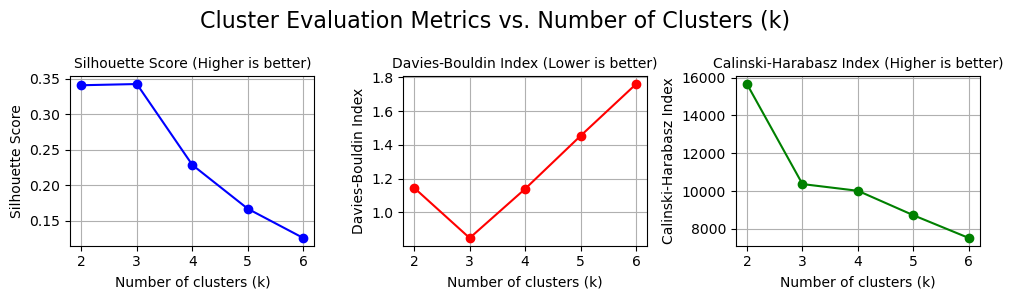

In [28]:
fig = plt.figure(figsize=(10, 3))
gs = gridspec.GridSpec(1, 3, figure=fig, height_ratios=[1])
fig.suptitle('Cluster Evaluation Metrics vs. Number of Clusters (k)', fontsize=16)

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(k_range, silhouette_scores, 'bo-')
ax1.set_xlabel('Number of clusters (k)', fontsize=10)
ax1.set_ylabel('Silhouette Score', fontsize=10)
ax1.set_title('Silhouette Score (Higher is better)', fontsize=10)
ax1.grid(True)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(k_range, davies_bouldin_scores, 'ro-')
ax2.set_xlabel('Number of clusters (k)', fontsize=10)
ax2.set_ylabel('Davies-Bouldin Index', fontsize=10)
ax2.set_title('Davies-Bouldin Index (Lower is better)', fontsize=10)
ax2.grid(True)

ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(k_range, calinski_harabasz_scores, 'go-')
ax3.set_xlabel('Number of clusters (k)', fontsize=10)
ax3.set_ylabel('Calinski-Harabasz Index', fontsize=10)
ax3.set_title('Calinski-Harabasz Index (Higher is better)', fontsize=10)
ax3.grid(True)

plt.tight_layout(); plt.show()

### 4.3 Creating and visualising customer segments

After selecting three clusters as the preferred option from the earlier evaluation, we used K-means to group customers based on similarities in their selected behavioural features.

We then used UMAP to create a two-dimensional visualisation of these groups. This makes it easier to see how the clusters are positioned relative to one another and whether customer behaviours appear distinct or overlap. The visualisation provides an overview of the groups, while further analysis is needed to understand the specific characteristics of each one.

In [47]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(X_kmeans_scaled)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1)
X_umap = reducer.fit_transform(X_kmeans_scaled)

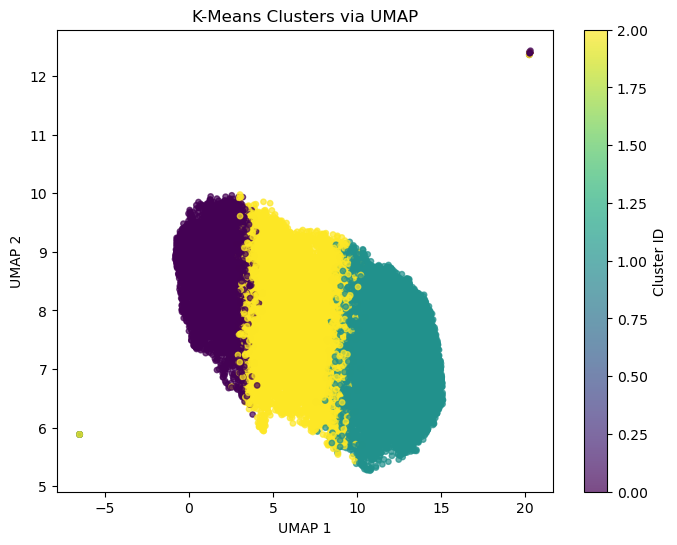

In [48]:
plt.figure(figsize=(8, 6)); scatter = plt.scatter(X_umap[:, 0],X_umap[:, 1],c=cluster_labels,cmap="viridis",s=15,alpha=0.7)
plt.colorbar(scatter, label="Cluster ID"); plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2"); plt.title("K-Means Clusters via UMAP"); plt.show()

**Interpreting the cluster evaluation results**

The evaluation measures produced mixed results when comparing the number of customer groups. Two clusters performed best on the silhouette and Calinski–Harabasz measures, while three clusters had the lowest Davies–Bouldin score. This meant there was no single option that performed best across all three measures.

Three clusters were selected for the next stage of the analysis to explore whether this grouping provided useful differences in customer behaviour. The resulting groups were then visualised and examined further to understand whether they offered meaningful insights for Le Shoppe.

In [31]:
kmean_groups = X_kmeans.copy(); kmean_groups['Cluster'] = cluster_labels
kmean_groups['Churned'] = y_kmeans

cluster_summary = kmean_groups.groupby('Cluster').mean(); 
cluster_table = cluster_summary.sort_values(by='Churned', ascending=True)

In [32]:
summary_values = {"Feature": ['Login_Frequency','Session_Duration_Avg', 'Pages_Per_Session', 'Wishlist_Items', 
                          'Total_Purchases','Average_Order_Value','Email_Open_Rate','Product_Reviews_Written',
                          'Social_Media_Engagement_Score','Mobile_App_Usage','Lifetime_Value','Credit_Balance','Churned'],
    "Min": [kmeans_df.Login_Frequency.min(), kmeans_df.Session_Duration_Avg.min(), kmeans_df.Pages_Per_Session.min(), kmeans_df.Wishlist_Items.min(), kmeans_df.Total_Purchases.min(), kmeans_df.Average_Order_Value.min(), kmeans_df.Email_Open_Rate.min(), kmeans_df.Product_Reviews_Written.min(), kmeans_df.Social_Media_Engagement_Score.min(), kmeans_df.Mobile_App_Usage.min(), kmeans_df.Lifetime_Value.min(), kmeans_df.Credit_Balance.min(), kmeans_df.Churned.min()],
    "Q1": [kmeans_df.Login_Frequency.quantile(0.25), kmeans_df.Session_Duration_Avg.quantile(0.25), kmeans_df.Pages_Per_Session.quantile(0.25), kmeans_df.Wishlist_Items.quantile(0.25), kmeans_df.Total_Purchases.quantile(0.25), kmeans_df.Average_Order_Value.quantile(0.25), kmeans_df.Email_Open_Rate.quantile(0.25), kmeans_df.Product_Reviews_Written.quantile(0.25), kmeans_df.Social_Media_Engagement_Score.quantile(0.25), kmeans_df.Mobile_App_Usage.quantile(0.25), kmeans_df.Lifetime_Value.quantile(0.25), kmeans_df.Credit_Balance.quantile(0.25), kmeans_df.Churned.quantile(0.25)],
    "Median": [kmeans_df.Login_Frequency.median(), kmeans_df.Session_Duration_Avg.median(), kmeans_df.Pages_Per_Session.median(), kmeans_df.Wishlist_Items.median(), kmeans_df.Total_Purchases.median(), kmeans_df.Average_Order_Value.median(), kmeans_df.Email_Open_Rate.median(), kmeans_df.Product_Reviews_Written.median(), kmeans_df.Social_Media_Engagement_Score.median(), kmeans_df.Mobile_App_Usage.median(), kmeans_df.Lifetime_Value.median(), kmeans_df.Credit_Balance.median(), kmeans_df.Churned.median()],    
    "Q3": [kmeans_df.Login_Frequency.quantile(0.75), kmeans_df.Session_Duration_Avg.quantile(0.75), kmeans_df.Pages_Per_Session.quantile(0.75), kmeans_df.Wishlist_Items.quantile(0.75), kmeans_df.Total_Purchases.quantile(0.75), kmeans_df.Average_Order_Value.quantile(0.75), kmeans_df.Email_Open_Rate.quantile(0.75), kmeans_df.Product_Reviews_Written.quantile(0.75), kmeans_df.Social_Media_Engagement_Score.quantile(0.75), kmeans_df.Mobile_App_Usage.quantile(0.75), kmeans_df.Lifetime_Value.quantile(0.75), kmeans_df.Credit_Balance.quantile(0.75), kmeans_df.Churned.quantile(0.75)],
    "Max": [kmeans_df.Login_Frequency.max(), kmeans_df.Session_Duration_Avg.max(), kmeans_df.Pages_Per_Session.max(), kmeans_df.Wishlist_Items.max(), kmeans_df.Total_Purchases.max(), kmeans_df.Average_Order_Value.max(), kmeans_df.Email_Open_Rate.max(), kmeans_df.Product_Reviews_Written.max(), kmeans_df.Social_Media_Engagement_Score.max(), kmeans_df.Mobile_App_Usage.max(), kmeans_df.Lifetime_Value.max(), kmeans_df.Credit_Balance.max(), kmeans_df.Churned.max()]}

summary_stats = pd.DataFrame(summary_values)

In [33]:
summary_stats.sort_values('Max', ascending=False).style.set_caption('Summary Statistics for Churn Data').format(precision=2)

,Feature,Min,Q1,Median,Q3,Max
5,Average_Order_Value,26.87,87.04,112.21,143.75,9487.43
10,Lifetime_Value,0.00,833.23,1299.56,1933.79,8987.24
11,Credit_Balance,0.00,1122.00,1987.00,2872.50,7160.00
4,Total_Purchases,-13.00,9.00,13.00,17.00,127.40
8,Social_Media_Engagement_Score,0.00,14.50,29.20,44.90,100.00
6,Email_Open_Rate,0.00,10.60,20.60,31.20,91.70
1,Session_Duration_Avg,1.00,20.10,27.30,35.20,72.10
9,Mobile_App_Usage,0.00,13.20,19.60,26.40,61.90
0,Login_Frequency,0.00,6.00,12.00,18.00,46.00
2,Pages_Per_Session,1.00,6.30,8.80,11.60,23.20


In [34]:
cluster_table.style.set_caption('Cluster Summary').format(precision=2)

,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Email_Open_Rate,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Lifetime_Value,Credit_Balance,Churned
Cluster,,,,,,,,,,,,,,
0,21.81,42.50,13.87,36.39,8.30,21.74,124.44,38.36,5.56,54.89,32.33,2418.30,3291.82,0.20
2,13.42,29.80,9.64,52.97,4.91,14.51,123.83,23.24,3.26,33.21,21.50,1580.46,2167.09,0.20
1,6.21,18.76,5.90,68.15,2.12,8.31,119.78,10.99,1.40,15.59,12.29,907.72,1249.04,0.38


In [35]:
risk_map = {0: "low", 1: "high", 2: "medium"}
kmean_groups['Churn_Risk'] = kmean_groups['Cluster'].map(risk_map)
kmean_groups.head(5)

,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Email_Open_Rate,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Lifetime_Value,Credit_Balance,Cluster,Churned,Churn_Risk
0,14.0,27.4,6.0,50.6,3.0,9.0,94.72,17.9,4.0,16.3,20.8,953.33,2278.0,2,0,medium
3,10.0,38.4,14.8,41.7,9.0,15.0,147.33,41.4,5.0,85.9,31.0,2340.92,2674.0,0,0,low
5,6.0,21.9,6.9,74.4,0.0,12.0,190.97,16.0,2.0,14.3,11.2,1995.43,2418.0,1,1,high
6,24.0,46.4,13.9,36.2,5.0,20.0,169.58,35.5,6.0,68.8,42.9,3003.57,2657.0,0,0,low
9,13.0,31.3,5.4,62.6,3.0,9.0,90.95,11.7,1.0,13.5,21.5,807.84,977.0,1,0,high


### 4.4 Interpreting the Customer Segments

The cluster summary helps us get a better understanding of how customers differ in their shopping behaviour and engagement with Le Shoppe. Looking at the average values for each group gives us an idea of which customers are more active, which spend more, and which groups may need more attention when it comes to retention.

**Cluster 0 — Higher engagement and customer value**

Customers in Cluster 0 are the most active group overall. They have the highest average login frequency (21.81), session duration (42.50) and pages per session (13.87). They also make the most purchases on average (21.74) and have the highest lifetime value (2,418.30). The average churn rate for this group is 20%. This suggests that these customers are generally more engaged with the business and contribute more value. Le Shoppe could focus on keeping these customers satisfied and encouraging them to continue shopping.

**Cluster 2 — Moderate engagement and customer value**

Cluster 2 sits between the other two groups for most engagement and purchasing measures. Customers in this group have an average of 14.51 purchases and a lifetime value of 1,580.46, with an average churn rate of 20%. This suggests there is an opportunity to encourage more repeat purchases and strengthen engagement through targeted campaigns or other incentives.

**Cluster 1 — Lower engagement and customer value**

Cluster 1 has the lowest average login frequency (6.21), session duration (18.76), pages per session (5.90) and total purchases (8.31). It also has the lowest average lifetime value (907.72) and the highest average churn rate at 38%. This group may be worth prioritising for re-engagement campaigns, as customers in this segment appear less active and have a higher proportion of churned customers.

**Business implications**

Overall, the results show that customers do not all interact with Le Shoppe in the same way. Some are more engaged and contribute more value, while others have lower activity levels and may be more likely to churn. Understanding these differences could help Le Shoppe make better decisions about how to approach retention, rather than using the same strategy for everyone.

It is important to remember that clustering groups customers based on similarities in their behaviour. It does not explain exactly why customers leave or predict with certainty which individual customers will churn. These findings provide useful context for the business, which can then be considered alongside the churn prediction models developed later in the project.

In [36]:
gmm = GaussianMixture(n_components=3, means_init=kmeans.cluster_centers_)
gmm.fit(X_kmeans_scaled) 

probabilities = gmm.predict_proba(X_kmeans_scaled)

prob_cols = [f'cluster_{i}_prob' for i in range(gmm.n_components)]
prob_df = pd.DataFrame(probabilities, columns=prob_cols, index=kmeans_df.index)

df_with_probs = pd.concat([kmeans_df, prob_df], axis=1)

prob_cols = ['cluster_0_prob', 'cluster_1_prob', 'cluster_2_prob']

df_with_probs['predicted_cluster'] = gmm.predict(X_kmeans_scaled)
df_with_probs['max_prob'] = df_with_probs[prob_cols].max(axis=1)

baseline_confidence = df_with_probs['max_prob'].mean()

ambiguity_rate = (df_with_probs['max_prob'] < 0.60).mean()

high_confidence_df = df_with_probs[df_with_probs['max_prob'] > 0.95]

med_confidence_df = df_with_probs[(df_with_probs['max_prob'] > 0.70) & (df_with_probs['max_prob'] <= 0.95)]

low_confidence_df = df_with_probs[df_with_probs['max_prob'] <= 0.70]

print(f"Baseline Average Confidence: {baseline_confidence:.2%}")
print(f"Baseline Ambiguity Rate: {ambiguity_rate:.2%}")
print(f"High Confidence Segments: {len(high_confidence_df)} out of {len(df_with_probs)} rows")
print(f"Medium Confidence Segments: {len(med_confidence_df)} out of {len(df_with_probs)} rows")
print(f"Low Confidence Segments: {len(low_confidence_df)} out of {len(df_with_probs)} rows")

Baseline Average Confidence: 92.42%
Baseline Ambiguity Rate: 4.33%
High Confidence Segments: 16966 out of 25123 rows
Medium Confidence Segments: 5852 out of 25123 rows
Low Confidence Segments: 2305 out of 25123 rows


### 4.5 Exploring Cluster Assignment Confidence

After identifying the customer segments using K-means, a Gaussian Mixture Model (GMM) was used to explore how confidently customers could be assigned to a cluster. This provides another way to understand whether customers fit clearly into one group or share characteristics across multiple groups.

The results showed an average assignment confidence of 92.42%, with an ambiguity rate of 4.33%. Out of 25,123 records, 16,966 were classified as high-confidence assignments, 5,852 as medium-confidence assignments and 2,305 as low-confidence assignments.

This suggests that most customers had a relatively clear cluster assignment, although some customers were harder to place into a single group. These less certain cases may be useful to consider when interpreting the customer segments.

It is important to note that these confidence scores relate to cluster membership, rather than the likelihood of a customer churning. They should therefore be interpreted separately from the supervised churn prediction models.

In [39]:
low_confidence_indices = low_confidence_df.index
difficult_df = churn_df.iloc[low_confidence_indices]
difficult_df.to_csv('difficult_cases.csv')

In [40]:
y_labels = kmean_groups['Cluster']
X_features = kmean_groups.drop(['Cluster','Churned','Churn_Risk'], axis=1, errors='ignore')

rf_helper2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf_helper2.fit(X_features, y_labels)

importances = rf_helper2.feature_importances_
feature_names = X_features.columns
feature_importance_df2 = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

feature_importance_df2 = feature_importance_df2.sort_values(by='Importance', ascending=False)
feature_importance_df2

,Feature,Importance
1,Session_Duration_Avg,0.174538
5,Total_Purchases,0.159901
10,Mobile_App_Usage,0.132064
2,Pages_Per_Session,0.117986
3,Cart_Abandonment_Rate,0.079248
0,Login_Frequency,0.066481
4,Wishlist_Items,0.058934
7,Email_Open_Rate,0.058292
9,Social_Media_Engagement_Score,0.044752
12,Credit_Balance,0.033638


### 4.6 Feature Importance Analysis

To get a better understanding of which customer behaviours were most useful for distinguishing between the customer groups, a Random Forest model was used to calculate feature importance. This helps show which variables contributed most to the model's decisions when separating the clusters.

The results show that **Session_Duration_Avg** had the highest feature importance (0.1745), followed by **Total_Purchases** (0.1599), **Mobile_App_Usage** (0.1321) and **Pages_Per_Session** (0.1180). **Cart_Abandonment_Rate** also contributed to the results, with an importance score of 0.0792.

This suggests that customer engagement and purchasing behaviour were particularly useful for distinguishing between the groups. Customers' time spent on the platform, purchase activity and use of the mobile app all helped differentiate the segments.

However, feature importance does not show whether a variable increases or decreases churn, and it does not establish a causal relationship. These results relate to the Random Forest model used for this clustering analysis, so they should be interpreted as an indication of which features helped distinguish the groups rather than a definitive ranking of churn drivers.

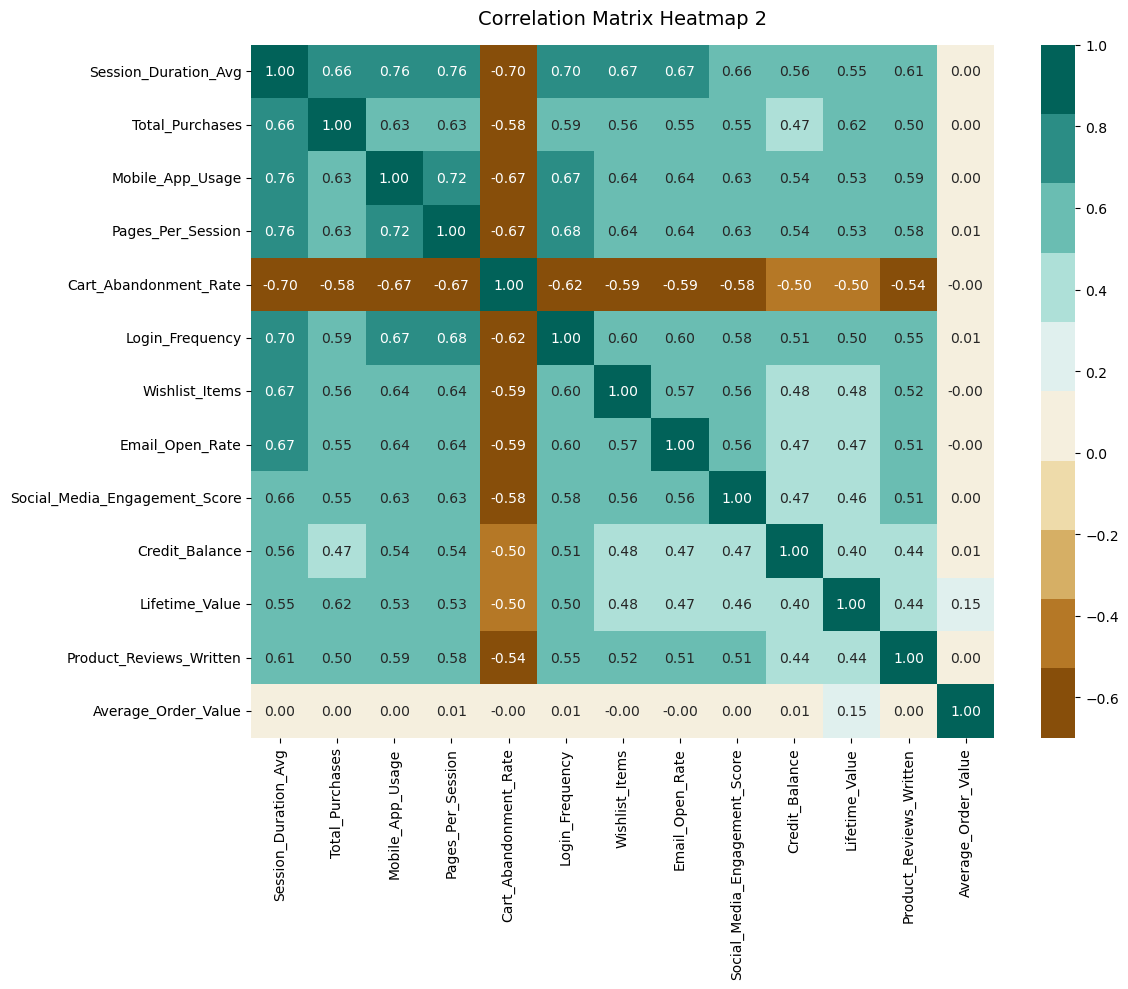

In [41]:
feature_names_grouping = feature_importance_df2['Feature'].tolist()

corr_matrix = churn_dataset_encoded[feature_names_grouping].corr()

plt.figure(figsize=(12, 10))
colormap = sns.color_palette("BrBG",10)

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap=colormap)

plt.title("Correlation Matrix Heatmap 2", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### 4.7 Correlation Analysis

The correlation heatmap was used to explore the relationships between the features included in the customer segmentation analysis. This helps identify which customer behaviours tend to move together and whether any features have particularly strong positive or negative relationships.

The strongest positive relationships include session duration and mobile app usage (0.76), session duration and pages per session (0.76), and mobile app usage and pages per session (0.72). This suggests that customers who spend longer on the platform may also browse more pages and make greater use of the mobile app.

Cart abandonment rate has negative correlations with several engagement measures, including session duration (-0.70), mobile app usage (-0.67) and pages per session (-0.67). This suggests that higher cart abandonment tends to be associated with lower engagement across these features.

Average order value has very little correlation with most of the other features in this heatmap, while lifetime value has a relatively weak relationship with many of the engagement measures. This shows that different features may capture different aspects of customer behaviour.

Overall, the heatmap highlights relationships between customer engagement, purchasing behaviour and cart abandonment. However, correlation does not establish cause and effect, and it does not tell us on its own which features are most useful for predicting churn. These findings provide additional context for the feature-importance results and the predictive modelling explored later in the project.

When it comes to grouping, based on the initial KMeans Clustering results, the important features are:

**Supporting features (highest correlation):**
- Session_Duration_Avg
- Total_Purchases
- Mobile_App_Usage
- Pages_Per_Session
- Cart_Abandonment_Rate
- Login_Frequency
- Wishlist_Items
- Email_Open_Rate

**Probably helpful (moderate correlation)**
- Lifetime_Value
- Social_Media_Engagement_Score
- Credit_Balance
- Product_Reviews_Written

**Droppable (very low correlation):**
- Average_Order_Value

In [42]:
print(churn_dataset.columns)

Index(['Age', 'Gender', 'Country', 'City', 'Membership_Years',
       'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session',
       'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases',
       'Average_Order_Value', 'Days_Since_Last_Purchase',
       'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate',
       'Customer_Service_Calls', 'Product_Reviews_Written',
       'Social_Media_Engagement_Score', 'Mobile_App_Usage',
       'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance',
       'Churned', 'Signup_Quarter'],
      dtype='object')


In [44]:
columns_to_keep = ['Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 
                   'Total_Purchases', 'Email_Open_Rate', 'Mobile_App_Usage', 'Lifetime_Value', 'Credit_Balance', 'Churned']
churn_df = churn_dataset[columns_to_keep]
churn_df.to_csv('churn_data_ready.csv', index=False)

In [45]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Login_Frequency        50000 non-null  float64
 1   Session_Duration_Avg   46601 non-null  float64
 2   Pages_Per_Session      47000 non-null  float64
 3   Cart_Abandonment_Rate  50000 non-null  float64
 4   Wishlist_Items         46000 non-null  float64
 5   Total_Purchases        50000 non-null  float64
 6   Email_Open_Rate        47472 non-null  float64
 7   Mobile_App_Usage       45000 non-null  float64
 8   Lifetime_Value         50000 non-null  float64
 9   Credit_Balance         44500 non-null  float64
 10  Churned                50000 non-null  int64  
dtypes: float64(10), int64(1)
memory usage: 4.2 MB


### 4.8 Final Feature Selection

After reviewing the feature-importance results and correlation heatmap, a final set of features was selected for the churn prediction analysis. The selection considered which variables helped distinguish between customer groups, how the features related to each other, and whether they were relevant to customer behaviour.

The final dataset retained 10 customer features: login frequency, average session duration, pages per session, cart abandonment rate, wishlist items, total purchases, email open rate, mobile app usage, lifetime value and credit balance. The `Churned` variable was retained as the target used to train the prediction models.

Average order value was excluded from the final feature set because it showed very little correlation with the other selected features in the heatmap. The aim of this process was to focus the subsequent modelling on a smaller group of variables that captured useful aspects of customer engagement, purchasing behaviour and value.